In [7]:
# File Loading and Preprocessing
import pandas as pd

games_all = pd.read_csv("data/steam_games_clean.csv")
games = games_all.copy()

print(games.shape)
print(games.head())


games["tags"] = games["tags"].fillna("")

games["tag_set"] = games["tags"].apply(
    lambda tags: {tag.strip() for tag in tags.split(",") if tag.strip()}
)

# Keep games with at least one tag
games = games[games["tag_set"].map(len) > 0].copy()

print(games[["name", "tag_set"]].head())

(23292, 10)
    app_id                                   name estimated_owners  price  \
0   496350  Supipara - Chapter 1 Spring Has Come!        0 - 20000   5.24   
1  1934300                     Armored Brigade II        0 - 20000  35.99   
2  1025440                     Fantasy General II  100000 - 200000  13.99   
3   328460                                Redline        0 - 20000   1.04   
4  2403000                 Fantasy Amusement Park        0 - 20000   5.99   

   positive  negative  avg_hours  median_hours               genres  \
0       252         3   0.133333      0.133333            Adventure   
1       117        13  11.250000     20.883333  Simulation,Strategy   
2      1025       210   8.150000      0.866667             Strategy   
3        74        35   3.383333      3.383333        Action,Racing   
4         0         0   1.466667      1.600000               Casual   

                                                tags  
0                  Adventure,Visual Novel,A

In [8]:
import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer

# Sample games so both methods use the same input
SAMPLE_SIZE = 1000
games = games.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)

# Convert each game's tags into a binary feature vector
# Example: {"Action", "RPG"} -> [1, 1, 0, ...]
mlb = MultiLabelBinarizer()
X = mlb.fit_transform(games["tag_set"]).astype(np.float32)

# Both HAC and K-Means will use Euclidean distance on X
# No Jaccard similarity/distance matrix is needed
print("Games:", X.shape[0])
print("Tag features:", X.shape[1])


Games: 1000
Tag features: 414


In [12]:
from sklearn.cluster import AgglomerativeClustering

# HAC: Euclidean distance between binary tag vectors
hac = AgglomerativeClustering(
    n_clusters=10,
    metric="euclidean",
    linkage="ward"
)

games["hac_cluster"] = hac.fit_predict(X)

print("HAC cluster sizes:")
print(games["hac_cluster"].value_counts().sort_index())


HAC cluster sizes:
hac_cluster
0    102
1    136
2     73
3    278
4     63
5    108
6     73
7     62
8     75
9     30
Name: count, dtype: int64


In [10]:
from sklearn.cluster import KMeans

# K-Means: uses Euclidean distance on the same X
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
games["kmeans_cluster"] = kmeans.fit_predict(X)

print("K-Means cluster sizes:")
print(games["kmeans_cluster"].value_counts().sort_index())


K-Means cluster sizes:
kmeans_cluster
0     70
1     93
2     91
3     82
4    257
5     83
6     52
7     88
8     97
9     87
Name: count, dtype: int64


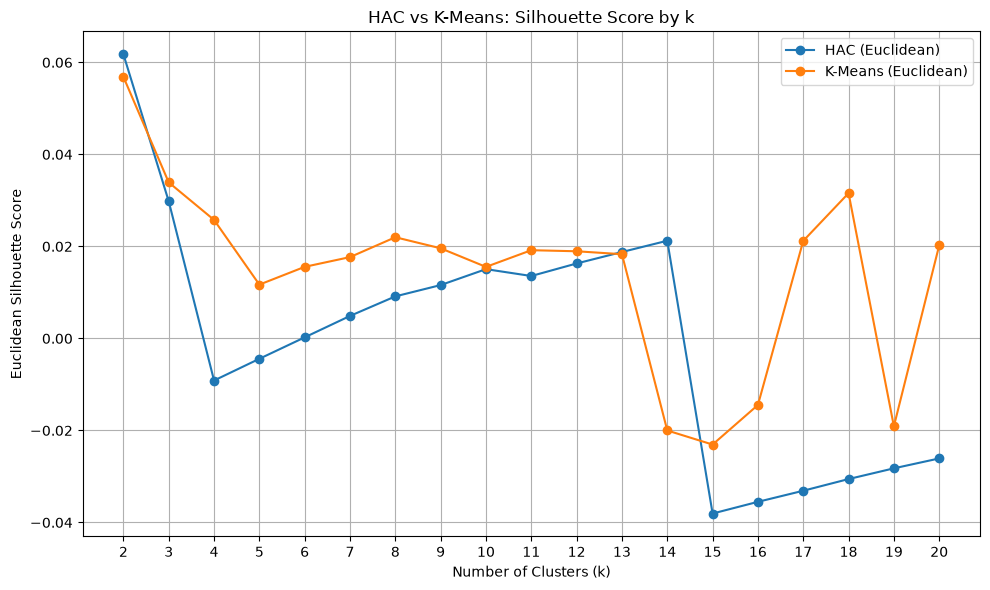

Best HAC k: 2, score: 0.0618
Best K-Means k: 2, score: 0.0569


In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

k_values = range(2, 21)
hac_scores = []
kmeans_scores = []

for k in k_values:
    # HAC on Euclidean tag vectors
    hac = AgglomerativeClustering(
        n_clusters=k,
        metric="euclidean",
        linkage="ward"
    )
    hac_labels = hac.fit_predict(X)

    # K-Means on the SAME Euclidean tag vectors
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_labels = kmeans.fit_predict(X)

    # Evaluate both with Euclidean silhouette scores
    hac_score = silhouette_score(X, hac_labels, metric="euclidean")
    kmeans_score = silhouette_score(X, kmeans_labels, metric="euclidean")

    hac_scores.append(hac_score)
    kmeans_scores.append(kmeans_score)

plt.style.use("default")
plt.figure(figsize=(10, 6))
plt.plot(k_values, hac_scores, marker="o", label="HAC (Euclidean)")
plt.plot(k_values, kmeans_scores, marker="o", label="K-Means (Euclidean)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Euclidean Silhouette Score")
plt.title("HAC vs K-Means: Silhouette Score by k")
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

best_hac_index = int(np.argmax(hac_scores))
best_kmeans_index = int(np.argmax(kmeans_scores))

print(f"Best HAC k: {list(k_values)[best_hac_index]}, score: {hac_scores[best_hac_index]:.4f}")
print(f"Best K-Means k: {list(k_values)[best_kmeans_index]}, score: {kmeans_scores[best_kmeans_index]:.4f}")


In [15]:
from sklearn.cluster import SpectralClustering

spectral = SpectralClustering(
    n_clusters=10,
    affinity="rbf",
    gamma=0.1,
    random_state=42,
    assign_labels="kmeans",
    n_init=10
)

games["spectral_cluster"] = spectral.fit_predict(X)

print("Spectral cluster sizes:")
print(games["spectral_cluster"].value_counts().sort_index())

Spectral cluster sizes:
spectral_cluster
0     91
1    254
2     80
3    118
4     82
5     88
6     71
7     83
8     66
9     67
Name: count, dtype: int64


In [16]:

spectral_scores = []

for k in k_values:
    spectral = SpectralClustering(
        n_clusters=k,
        affinity="rbf",
        gamma=0.1,
        random_state=42,
        assign_labels="kmeans",
        n_init=10
    )

    labels = spectral.fit_predict(X)

    score = silhouette_score(
        X, labels, metric="euclidean"
    )

    spectral_scores.append(score)


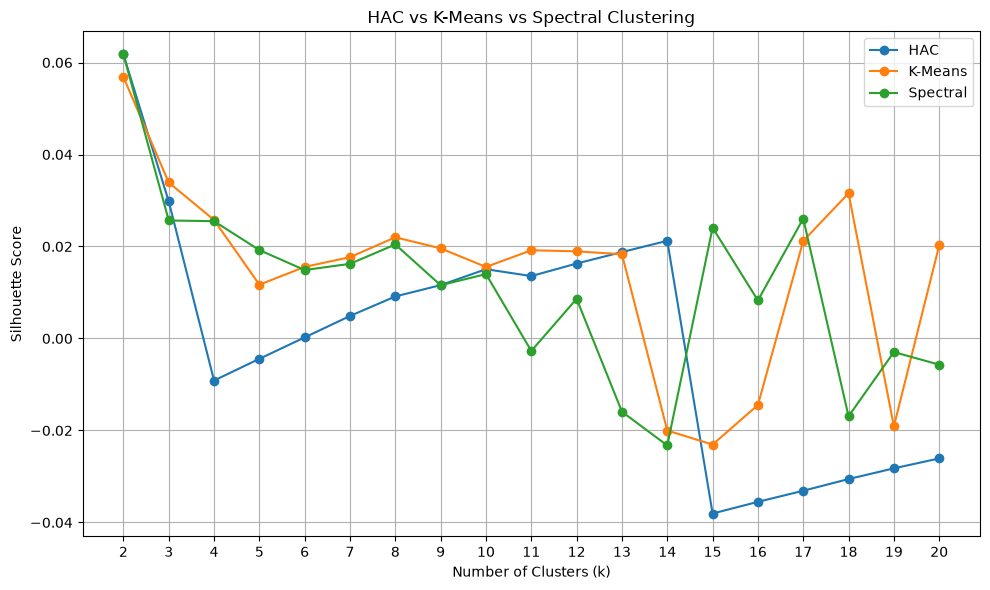

Best Spectral k: 2
Best Spectral score: 0.0618


In [17]:

plt.figure(figsize=(10, 6))

plt.plot(k_values, hac_scores, marker="o", label="HAC")
plt.plot(k_values, kmeans_scores, marker="o", label="K-Means")
plt.plot(k_values, spectral_scores, marker="o", label="Spectral")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("HAC vs K-Means vs Spectral Clustering")

plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Find best k for Spectral Clustering
best_index = np.argmax(spectral_scores)
best_k = list(k_values)[best_index]

print("Best Spectral k:", best_k)
print("Best Spectral score:", round(spectral_scores[best_index], 4))
